# 06 · ¿Pronosticar el día siguiente o la semana siguiente? — efecto del horizonte sobre los lags

**Responsable:** Joan · **Plan:** `project_plan_crisp_dm.md` §2.2 (horizonte) y §6.4 (lags) · **Entradas:** los dos finalistas del Sprint 3.

**Pregunta de negocio:** el modelo con lags usa la demanda observada hace 24 h (`lag_24`) y hace 168 h (`lag_168`). Cuáles están disponibles depende de **cuándo se emite el pronóstico y para qué horas**:

| Horizonte | `lag_24` | `lag_168` |
| :--- | :---: | :---: |
| Día siguiente, pronóstico emitido a las 00:00 (las 24 h del día D) | disponible | disponible |
| Día siguiente, pronóstico emitido antes (p. ej. a las 18:00 del día anterior) | **falta para las últimas horas del día** | disponible |
| **Semana siguiente** (168 h) | **no disponible** (salvo el primer día) | disponible: la semana anterior ya está completa |

Se mide cuánto rinde cada escenario con la **misma validación** (`TimeSeriesSplit`, `gap=24`, solo train, el test no se carga). No se re-tunea ningún modelo: se usan los hiperparámetros ya registrados (fichas 4 y 14), por lo que los escenarios distintos a «ambos lags» pueden estar algo penalizados. **Qué horizonte adoptar es decisión de Joan y del grupo**; esto solo aporta la evidencia.

Atención: esta medición usa el clima **observado**. En un pronóstico a una semana el clima también sería un pronóstico, mucho menos preciso que a un día; ese efecto se mide en la validación operativa (§8.4) y **no** está en estos números, de modo que el escenario semanal está sobrestimado más que el diario.

## 1) Preparación

In [1]:
import sys, json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from lightgbm import LGBMRegressor
from sklearn.base import clone
from sklearn.pipeline import Pipeline

for _p in [Path.cwd(), *Path.cwd().parents]:
    if (_p / "config" / "config.py").exists():
        RAIZ = _p
        break
else:
    raise FileNotFoundError("No se encontró config/config.py")
sys.path.insert(0, str(RAIZ))

from config.config import CONFIG, RANDOM_STATE
from src.data_loader import load_data, temporal_split, separar_xy
from src.features import build_preprocessor, agregar_lags
from src.evaluate import ajustar, predecir_bicis, calcular_metricas, get_cv, validar_temporal

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid")
FIG_DIR = CONFIG["dir_reports"] / "joan" / "figuras"; FIG_DIR.mkdir(parents=True, exist_ok=True)
def guardar(fig, nombre): fig.savefig(FIG_DIR / f"{nombre}.png", dpi=130, bbox_inches="tight")

df = load_data()
train, test = temporal_split(df)
del test                                          # el test no se usa
df_l = agregar_lags(df, horas=(24, 168, 336))     # lag_336 = misma hora de hace dos semanas (otra opción para el horizonte semanal)
X_all, y_all = separar_xy(temporal_split(df_l)[0])
y_all = np.asarray(y_all, dtype=float)
cv24 = get_cv(gap=CONFIG["lgbm"]["gap_con_lags"])
cfg_automl = json.load(open(CONFIG["dir_reports"] / "jose" / "automl_config.json", encoding="utf-8"))
print("X:", X_all.shape, "| columnas lag:", [c for c in X_all.columns if c.startswith("lag_")], "| validación:", cv24)

X: (13003, 16) | columnas lag: ['lag_24', 'lag_168', 'lag_336'] | validación: TimeSeriesSplit(gap=24, max_train_size=None, n_splits=5, test_size=1460)


### Punto de control 1

In [2]:
assert X_all.index.max() <= pd.Timestamp(CONFIG["ultima_hora_train"])
assert not {"cnt", "casual", "registered", "instant"} & set(X_all.columns)
t = X_all.index[2000]
for h in (24, 168, 336):
    assert np.isclose(X_all.loc[t, f"lag_{h}"], df.loc[t - pd.Timedelta(hours=h), "cnt"], equal_nan=True)
print(" Lags calculados solo con el pasado; train sin test. NaN por lag:", {c: int(X_all[c].isna().sum()) for c in X_all.columns if c.startswith('lag_')})

 Lags calculados solo con el pasado; train sin test. NaN por lag: {'lag_24': 132, 'lag_168': 265, 'lag_336': 431}


## 2) Escenarios
Cada escenario define **qué lags existen en el momento de pronosticar**. «Emitido a las 18:00» significa que se conoce la demanda hasta las 17:00 del día anterior, por lo que `lag_24` **no existe para las horas 18 a 23** del día pronosticado (queda NaN; LightGBM lo admite). Para ese caso se mide también el caso desfavorable: el modelo se **entrena con lags completos** y se **usa con `lag_24` ausente** (qué pasa si el sistema falla en producción).

In [3]:
def con_corte(X, hora_corte=18):
    """Copia de X con lag_24 = NaN en las horas >= hora_corte (pronóstico emitido a esa hora del día anterior)."""
    Xm = X.copy(); Xm.loc[Xm["hr"] >= hora_corte, "lag_24"] = np.nan; return Xm

X_corte = con_corte(X_all)
print("Filas con lag_24 anulado por el corte de las 18:00:", int((X_corte['hr'] >= 18).sum()), "de", len(X_corte))

ESCENARIOS = {   # nombre -> (X, lags que entran al modelo)
    "Sin lags": (X_all, ()),
    "Solo lag_168 (semana)": (X_all, ("lag_168",)),
    "lag_168 + lag_336 (semana)": (X_all, ("lag_168", "lag_336")),
    "Solo lag_24": (X_all, ("lag_24",)),
    "lag_24 + lag_168 (día, emitido 00:00)": (X_all, ("lag_24", "lag_168")),
    "lag_24 + lag_168 (día, emitido 18:00)": (X_corte, ("lag_24", "lag_168")),
    "lag_24 + lag_168 + lag_336 (día, emitido 00:00)": (X_all, ("lag_24", "lag_168", "lag_336")),
    "lag_24 + lag_168 + lag_336 (día, emitido 18:00)": (X_corte, ("lag_24", "lag_168", "lag_336")),
}
CASO_FALLA = "lag_24 + lag_168 (día, emitido 18:00; entrenado con lags completos)"
CASO_FALLA3 = "lag_24 + lag_168 + lag_336 (emitido 18:00; entrenado con lags completos)"
MODELOS = {
    "LightGBM manual": lambda: LGBMRegressor(**{**CONFIG["lgbm"]["params_base"], **CONFIG["lgbm"]["params_tuneados"]}),
    "AutoML (config sin lags)": lambda: lgbm_flaml(cfg_automl["sin_lags"]["mejor_config"]),
    "AutoML (config con lags)": lambda: lgbm_flaml(cfg_automl["con_lags"]["mejor_config"]),
}
def lgbm_flaml(config):
    c = dict(config); lmb = c.pop("log_max_bin")
    return LGBMRegressor(max_bin=(1 << int(round(lmb))) - 1, n_jobs=-1, verbose=-1, **c)
def pipe(modelo, lags): return Pipeline([("prep", build_preprocessor(lags=tuple(lags))), ("modelo", MODELOS[modelo]())])

Filas con lag_24 anulado por el corte de las 18:00: 3270 de 13003


### Medición

In [4]:
PF = {}                      # (modelo, escenario) -> RMSLE por fold
for m in MODELOS:
    for esc, (X, lags) in ESCENARIOS.items():
        pf, rs = validar_temporal(pipe(m, lags), X, y_all, nombre=f"{m} | {esc}", cv=cv24)
        PF[(m, esc)] = pf["rmsle"].to_numpy()
    # Caso de falla: entrenar con lags completos y predecir con lag_24 ausente en las horas >= 18
    for caso, lags in [(CASO_FALLA, ("lag_24", "lag_168")), (CASO_FALLA3, ("lag_24", "lag_168", "lag_336"))]:
        r = []
        for i_tr, i_va in cv24.split(X_all):
            mod = ajustar(pipe(m, lags), X_all.iloc[i_tr], y_all[i_tr], True)
            r.append(calcular_metricas(y_all[i_va], predecir_bicis(mod, X_corte.iloc[i_va], True))["rmsle"])
        PF[(m, caso)] = np.array(r)
ESC_TODOS = list(ESCENARIOS) + [CASO_FALLA, CASO_FALLA3]
media = pd.DataFrame({m: {e: PF[(m, e)].mean() for e in ESC_TODOS} for m in MODELOS})
desv = pd.DataFrame({m: {e: PF[(m, e)].std(ddof=1) for e in ESC_TODOS} for m in MODELOS})
tabla = pd.concat({"RMSLE medio": media, "± std folds": desv}, axis=1)
display(tabla.round(4))

RMSLE medio  \
                                                   LightGBM manual   
Sin lags                                                    0.4562   
Solo lag_168 (semana)                                       0.4143   
lag_168 + lag_336 (semana)                                  0.3893   
Solo lag_24                                                 0.4167   
lag_24 + lag_168 (día, emitido 00:00)                       0.3905   
lag_24 + lag_168 (día, emitido 18:00)                       0.4015   
lag_24 + lag_168 + lag_336 (día, emitido 00:00)             0.3732   
lag_24 + lag_168 + lag_336 (día, emitido 18:00)             0.3823   
lag_24 + lag_168 (día, emitido 18:00; entrenado...          0.4131   
lag_24 + lag_168 + lag_336 (emitido 18:00; entr...          0.3862   

                                                                             \
                                                   AutoML (config sin lags)   
Sin lags                                                             0.4417   
Solo lag_168 (semana)                                                0.4075   
lag_168 + lag_336 (semana)                                           0.3863   
Solo lag_24                                                          0.4091   
lag_24 + lag_168 (día, emitido 00:00)                                0.3855   
lag_24 + lag_168 (día, emitido 18:00)                                0.3975   
lag_24 + lag_168 + lag_336 (día, emitido 00:00)                      0.3738   
lag_24 + lag_168 + lag_336 (día, emitido 18:00)                      0.3826   
lag_24 + lag_168 (día, emitido 18:00; entrenado...                   0.4173   
lag_24 + lag_168 + lag_336 (emitido 18:00; entr...                   0.3985   

                                                                             \
                                                   AutoML (config con lags)   
Sin lags                                                             0.4491   
Solo lag_168 (semana)                                                0.4154   
lag_168 + lag_336 (semana)                                           0.3918   
Solo lag_24                                                          0.4126   
lag_24 + lag_168 (día, emitido 00:00)                                0.3876   
lag_24 + lag_168 (día, emitido 18:00)                                0.4014   
lag_24 + lag_168 + lag_336 (día, emitido 00:00)                      0.3766   
lag_24 + lag_168 + lag_336 (día, emitido 18:00)                      0.3838   
lag_24 + lag_168 (día, emitido 18:00; entrenado...                   0.4460   
lag_24 + lag_168 + lag_336 (emitido 18:00; entr...                   0.4077   

                                                       ± std folds  \
                                                   LightGBM manual   
Sin lags                                                    0.1905   
Solo lag_168 (semana)                                       0.1191   
lag_168 + lag_336 (semana)                                  0.0774   
Solo lag_24                                                 0.1323   
lag_24 + lag_168 (día, emitido 00:00)                       0.0853   
lag_24 + lag_168 (día, emitido 18:00)                       0.0982   
lag_24 + lag_168 + lag_336 (día, emitido 00:00)             0.0566   
lag_24 + lag_168 + lag_336 (día, emitido 18:00)             0.0646   
lag_24 + lag_168 (día, emitido 18:00; entrenado...          0.0957   
lag_24 + lag_168 + lag_336 (emitido 18:00; entr...          0.0614   

                                                                             \
                                                   AutoML (config sin lags)   
Sin lags                                                             0.1945   
Solo lag_168 (semana)                                                0.1192   
lag_168 + lag_336 (semana)                                           0.0833   
Solo lag_24                                                          0.1343   
l

### Punto de control 2: la medición reproduce lo ya registrado

In [5]:
# Ficha 7 (LightGBM, gap=24): sin lags 0.4562, lag_24 0.4167, lag_168 0.4143, ambos 0.3905
assert abs(media.loc["Sin lags", "LightGBM manual"] - 0.4562) < 6e-4
assert abs(media.loc["Solo lag_24", "LightGBM manual"] - 0.4167) < 6e-4
assert abs(media.loc["Solo lag_168 (semana)", "LightGBM manual"] - 0.4143) < 6e-4
assert abs(media.loc["lag_24 + lag_168 (día, emitido 00:00)", "LightGBM manual"] - 0.3905) < 6e-4
# Ficha 14 / notebook 05 (AutoML con lags, gap=24): 0.3876
assert abs(media.loc["lag_24 + lag_168 (día, emitido 00:00)", "AutoML (config con lags)"] - 0.3876) < 6e-4
assert all(len(v) == 5 and np.isfinite(v).all() for v in PF.values())
print(" Los escenarios conocidos reproducen las fichas 7 y 14; los demás son nuevos.")

 Los escenarios conocidos reproducen las fichas 7 y 14; los demás son nuevos.


## 3) Comparación contra «sin lags» (misma validación, mismo modelo)
Regla de adopción del equipo: mejora media del RMSLE ≥ 0.002 y peor en ≤ 1 de los 5 folds.

In [6]:
regla = CONFIG["regla_adopcion"]; filas = []
for m in MODELOS:
    ref = PF[(m, "Sin lags")]
    for e in ESC_TODOS:
        if e == "Sin lags": continue
        d = ref - PF[(m, e)]
        filas.append({"modelo": m, "escenario": e, "RMSLE": PF[(m, e)].mean(), "mejora vs sin lags": d.mean(), "mejora %": d.mean() / ref.mean() * 100,
                      "folds mejor": int((d > 1e-9).sum()), "folds peor": int((d < -1e-9).sum()),
                      "cumple regla": bool(d.mean() >= regla["min_mejora_rmsle"] and (d < -1e-9).sum() <= regla["max_folds_peor"])})
comp = pd.DataFrame(filas)
display(comp.round(4))
for m in MODELOS:
    print(m, "- RMSLE por fold:"); display(pd.DataFrame({e: PF[(m, e)] for e in ESC_TODOS}, index=range(1, 6)).T.round(4))

,modelo,escenario,RMSLE,mejora vs sin lags,mejora %,folds mejor,folds peor,cumple regla
0,LightGBM manual,Solo lag_168 (semana),0.4143,0.0419,9.1778,3,2,False
1,LightGBM manual,lag_168 + lag_336 (semana),0.3893,0.0669,14.6709,2,3,False
2,LightGBM manual,Solo lag_24,0.4167,0.0395,8.6684,5,0,True
3,LightGBM manual,"lag_24 + lag_168 (día, emitido 00:00)",0.3905,0.0658,14.4153,4,1,True
4,LightGBM manual,"lag_24 + lag_168 (día, emitido 18:00)",0.4015,0.0547,11.9868,3,2,False
5,LightGBM manual,"lag_24 + lag_168 + lag_336 (día, emitido 00:00)",0.3732,0.0831,18.2041,3,2,False
6,LightGBM manual,"lag_24 + lag_168 + lag_336 (día, emitido 18:00)",0.3823,0.0739,16.1920,3,2,False
7,LightGBM manual,"lag_24 + lag_168 (día, emitido 18:00; entrenad...",0.4131,0.0431,9.4486,2,3,False
8,LightGBM manual,lag_24 + lag_168 + lag_336 (emitido 18:00; ent...,0.3862,0.0700,15.3420,2,3,False
9,AutoML (config sin lags),Solo lag_168 (semana),0.4075,0.0343,7.7565,2,3,False


LightGBM manual - RMSLE por fold:


,1,2,3,4,5
Sin lags,0.3821,0.4395,0.7786,0.4061,0.2747
Solo lag_168 (semana),0.3796,0.4554,0.5969,0.3565,0.2833
lag_168 + lag_336 (semana),0.3938,0.4481,0.4775,0.3384,0.2888
Solo lag_24,0.3818,0.4106,0.6339,0.3837,0.2734
"lag_24 + lag_168 (día, emitido 00:00)",0.3751,0.4374,0.5044,0.3572,0.2782
"lag_24 + lag_168 (día, emitido 18:00)",0.3771,0.4420,0.5457,0.3583,0.2845
"lag_24 + lag_168 + lag_336 (día, emitido 00:00)",0.3902,0.4311,0.4117,0.3412,0.2916
"lag_24 + lag_168 + lag_336 (día, emitido 18:00)",0.3947,0.4382,0.4432,0.3442,0.2914
"lag_24 + lag_168 (día, emitido 18:00; entrenado con lags completos)",0.3898,0.4633,0.5477,0.3671,0.2977
lag_24 + lag_168 + lag_336 (emitido 18:00; entrenado con lags completos),0.3937,0.4417,0.4443,0.3506,0.3008


AutoML (config sin lags) - RMSLE por fold:


,1,2,3,4,5
Sin lags,0.3738,0.4395,0.7707,0.3628,0.2619
Solo lag_168 (semana),0.3793,0.4536,0.5882,0.3356,0.2807
lag_168 + lag_336 (semana),0.3814,0.4490,0.4869,0.3311,0.2832
Solo lag_24,0.3779,0.4132,0.6292,0.3572,0.2676
"lag_24 + lag_168 (día, emitido 00:00)",0.3787,0.4291,0.5032,0.3365,0.2801
"lag_24 + lag_168 (día, emitido 18:00)",0.3793,0.4473,0.5493,0.3330,0.2786
"lag_24 + lag_168 + lag_336 (día, emitido 00:00)",0.3810,0.4370,0.4378,0.3279,0.2852
"lag_24 + lag_168 + lag_336 (día, emitido 18:00)",0.3833,0.4489,0.4669,0.3333,0.2808
"lag_24 + lag_168 (día, emitido 18:00; entrenado con lags completos)",0.3917,0.4462,0.5444,0.3763,0.3277
lag_24 + lag_168 + lag_336 (emitido 18:00; entrenado con lags completos),0.3850,0.4462,0.4777,0.3500,0.3335


AutoML (config con lags) - RMSLE por fold:


,1,2,3,4,5
Sin lags,0.4167,0.4194,0.7511,0.3944,0.2641
Solo lag_168 (semana),0.4065,0.4432,0.5765,0.3611,0.2895
lag_168 + lag_336 (semana),0.4052,0.4507,0.4634,0.3505,0.2891
Solo lag_24,0.3978,0.4021,0.5937,0.3907,0.2784
"lag_24 + lag_168 (día, emitido 00:00)",0.3943,0.4234,0.4736,0.3581,0.2885
"lag_24 + lag_168 (día, emitido 18:00)",0.4019,0.4292,0.5222,0.3641,0.2897
"lag_24 + lag_168 + lag_336 (día, emitido 00:00)",0.4019,0.4337,0.4182,0.3393,0.2898
"lag_24 + lag_168 + lag_336 (día, emitido 18:00)",0.4055,0.4354,0.4419,0.3466,0.2897
"lag_24 + lag_168 (día, emitido 18:00; entrenado con lags completos)",0.4391,0.4437,0.5813,0.4167,0.3491
lag_24 + lag_168 + lag_336 (emitido 18:00; entrenado con lags completos),0.4125,0.4478,0.4819,0.3667,0.3298


### Punto de control 3

In [7]:
assert comp.shape[0] == 3 * (len(ESC_TODOS) - 1)
ref_base = 0.5586   # baseline con gap=24 (notebook 05)
mejor_dia = media.loc["lag_24 + lag_168 (día, emitido 00:00)"].min(); mejor_sem = media.loc[["Solo lag_168 (semana)", "lag_168 + lag_336 (semana)"]].min().min()
assert (media.drop(index=["Sin lags"]).max(axis=1) < media.loc["Sin lags"].max()).all(), "todo escenario con lags debería mejorar al peor modelo sin lags"
assert abs(mejor_dia - mejor_sem) < 0.02, "la diferencia día-semana es menor que la desviación entre folds"
print(f" Mejor día (00:00): {mejor_dia:.4f} | mejor semana: {mejor_sem:.4f} | mejor sin lags: {media.loc['Sin lags'].min():.4f} | baseline: {ref_base}")

 Mejor día (00:00): 0.3855 | mejor semana: 0.3863 | mejor sin lags: 0.4417 | baseline: 0.5586


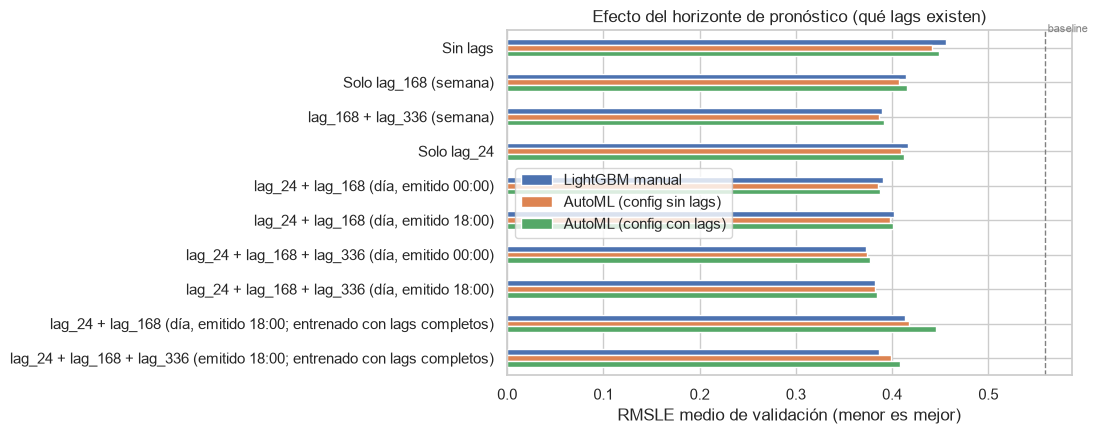

In [8]:
fig, ax = plt.subplots(figsize=(11, 4.5))
orden = ESC_TODOS
media.loc[orden].plot.barh(ax=ax); ax.invert_yaxis(); ax.set_xlabel("RMSLE medio de validación (menor es mejor)")
ax.axvline(0.5586, color="gray", ls="--", lw=1); ax.text(0.5586, -0.45, " baseline", color="gray", fontsize=8)
ax.set_title("Efecto del horizonte de pronóstico (qué lags existen)"); plt.tight_layout(); guardar(fig, "17_horizonte_lags"); plt.show()

## 4) Candidatos finales: incertidumbre de las diferencias
Se comparan con las **predicciones fuera de muestra** (7 300 horas de validación) tres candidatos: **A** = LightGBM manual con los tres lags emitido a las 00:00 (día); **B** = AutoML (config sin lags) con los tres lags (día); **C** = LightGBM manual con `lag_168` + `lag_336` (semana). Bootstrap de **días completos** (2 000 réplicas, semilla 42) sobre el RMSLE agrupado; negativo = el primero es mejor.

In [9]:
def oof(pipe_, X, cv_):
    partes = []
    for k, (i_tr, i_va) in enumerate(cv_.split(X), start=1):
        m = ajustar(clone(pipe_), X.iloc[i_tr], y_all[i_tr], True)
        partes.append(pd.DataFrame({"fold": k, "y": y_all[i_va], "pred": predecir_bicis(m, X.iloc[i_va], True)}, index=X.index[i_va]))
    return pd.concat(partes)

def err_log(o): return np.log1p(o["y"].to_numpy()) - np.log1p(o["pred"].to_numpy())

def bootstrap_dias(oa, ob, B=2000, seed=RANDOM_STATE):
    dia = oa.index.normalize(); dias = np.unique(dia)
    sa = pd.Series(err_log(oa) ** 2, index=oa.index).groupby(dia).sum().reindex(dias).to_numpy()
    sb = pd.Series(err_log(ob) ** 2, index=oa.index).groupby(dia).sum().reindex(dias).to_numpy()
    n = pd.Series(1, index=oa.index).groupby(dia).sum().reindex(dias).to_numpy()
    idx = np.random.default_rng(seed).integers(0, len(dias), size=(B, len(dias)))
    d = np.sqrt(sa[idx].sum(1) / n[idx].sum(1)) - np.sqrt(sb[idx].sum(1) / n[idx].sum(1))
    return float(np.sqrt(sa.sum() / n.sum()) - np.sqrt(sb.sum() / n.sum())), np.percentile(d, [2.5, 97.5]).round(4).tolist(), float((d < 0).mean())

L3, L2S = ("lag_24", "lag_168", "lag_336"), ("lag_168", "lag_336")
CAND = {"A: LightGBM manual · 3 lags · día (00:00)": oof(pipe("LightGBM manual", L3), X_all, cv24),
        "B: AutoML (config sin lags) · 3 lags · día (00:00)": oof(pipe("AutoML (config sin lags)", L3), X_all, cv24),
        "C: LightGBM manual · lag_168 + lag_336 · semana": oof(pipe("LightGBM manual", L2S), X_all, cv24)}
nombres = list(CAND)
filas = []
for a, b in [(0, 1), (0, 2)]:
    p, ic, pr = bootstrap_dias(CAND[nombres[a]], CAND[nombres[b]])
    fa = PF[("LightGBM manual", "lag_24 + lag_168 + lag_336 (día, emitido 00:00)")] if a == 0 else None
    filas.append({"comparación": f"{nombres[a][:1]} − {nombres[b][:1]} (negativo: {nombres[a][:1]} mejor)", "RMSLE agrupado": p, "IC95% bootstrap": tuple(ic), "P(el primero mejor)": pr})
display(pd.DataFrame(filas).round(4))
resumen = pd.DataFrame({n: {"RMSLE medio por fold": o.groupby("fold").apply(lambda g: np.sqrt(np.mean(err_log(g) ** 2))).mean(),
                            "peor fold": o.groupby("fold").apply(lambda g: np.sqrt(np.mean(err_log(g) ** 2))).max(),
                            "sesgo medio (log)": err_log(o).mean()} for n, o in CAND.items()}).T
display(resumen.round(4))
d_ac = (PF[("LightGBM manual", "lag_168 + lag_336 (semana)")] - PF[("LightGBM manual", "lag_24 + lag_168 + lag_336 (día, emitido 00:00)")])
print("Semana − día, por fold (LightGBM manual):", d_ac.round(4).tolist(), "| media", round(d_ac.mean(), 4), "| el día es mejor en", int((d_ac > 0).sum()), "de 5 folds")

,comparación,RMSLE agrupado,IC95% bootstrap,P(el primero mejor)
0,A − B (negativo: A mejor),-0.0020,"(-0.0081, 0.0039)",0.7525
1,A − C (negativo: A mejor),-0.0188,"(-0.0243, -0.0133)",1.0000


,RMSLE medio por fold,peor fold,sesgo medio (log)
A: LightGBM manual · 3 lags · día (00:00),0.3732,0.4311,0.0881
B: AutoML (config sin lags) · 3 lags · día (00:00),0.3738,0.4378,0.0963
C: LightGBM manual · lag_168 + lag_336 · semana,0.3893,0.4775,0.1052


Semana − día, por fold (LightGBM manual): [0.0035, 0.0169, 0.0657, -0.0028, -0.0028] | media 0.0161 | el día es mejor en 3 de 5 folds


### Punto de control 4

In [10]:
for n, o in CAND.items():
    assert len(o) == 5 * 1460 and o.index.equals(CAND[nombres[0]].index)
assert abs(resumen.iloc[0, 0] - media.loc["lag_24 + lag_168 + lag_336 (día, emitido 00:00)", "LightGBM manual"]) < 1e-9
assert abs(resumen.iloc[2, 0] - media.loc["lag_168 + lag_336 (semana)", "LightGBM manual"]) < 1e-9
print(" Los candidatos reproducen la tabla de la sección 2 y comparten las mismas 7 300 horas.")

 Los candidatos reproducen la tabla de la sección 2 y comparten las mismas 7 300 horas.


## 5) Interpretación y selección

RMSLE medio de validación (`gap=24`, solo train; menor es mejor; entre paréntesis, desviación entre folds):

| Escenario | LightGBM manual | AutoML (config sin lags) | AutoML (config con lags) |
| :--- | :---: | :---: | :---: |
| Sin lags | 0.4562 (0.1905) | 0.4417 (0.1945) | 0.4491 (0.1805) |
| Semana: `lag_168` | 0.4143 (0.1191) | 0.4075 (0.1192) | 0.4154 (0.1068) |
| Semana: `lag_168` + `lag_336` | 0.3893 (0.0774) | 0.3863 (0.0833) | 0.3918 (0.0725) |
| Día: `lag_24` | 0.4167 (0.1323) | 0.4091 (0.1343) | 0.4126 (0.1136) |
| Día, 00:00: `lag_24` + `lag_168` | 0.3905 (0.0853) | 0.3855 (0.0856) | 0.3876 (0.0697) |
| Día, 18:00: `lag_24` + `lag_168` | 0.4015 (0.0982) | 0.3975 (0.1051) | 0.4014 (0.0855) |
| **Día, 00:00: los tres lags** | **0.3732 (0.0566)** | **0.3738 (0.0673)** | **0.3766 (0.0604)** |
| Día, 18:00: los tres lags | 0.3823 (0.0646) | 0.3826 (0.0779) | 0.3838 (0.0647) |
| Falla de `lag_24` (entrenado con 2 lags) | 0.4131 | 0.4173 | 0.4460 |
| **Falla de `lag_24` (entrenado con los 3 lags)** | **0.3862** | 0.3985 | 0.4077 |

1. **Los tres lags son la mejor combinación en los tres modelos.** LightGBM manual baja a **0.3732 ± 0.0566** (frente a 0.3905 con dos lags y 0.4562 sin lags: 18.2 % menos que sin lags) y es también la **menor desviación entre folds** de toda la tabla. El fold 3, el más difícil, pasa de 0.5044 (dos lags) a 0.4117. Por fold, LightGBM con los tres lags: 0.3902, 0.4311, 0.4117, 0.3412 y 0.2916.
2. **Con los tres lags desaparece la ventaja de AutoML.** LightGBM manual (0.3732) y la configuración de AutoML sin lags (0.3738) empatan: diferencia agrupada −0.0020, IC95 % [−0.0081, 0.0039] por bootstrap de días (el primero es mejor en el 75 % de las réplicas).
3. **LightGBM manual es mucho más robusto si falta `lag_24`.** Entrenado con los tres lags y usado sin `lag_24`, queda en 0.3862, un resultado que sigue siendo mejor que cualquier esquema de dos lags; las configuraciones de AutoML suben a 0.3985 y 0.4077. Tener `lag_168` y `lag_336` amortigua la pérdida.
4. **Emitir a las 18:00 cuesta ≈ 0.007–0.009** con los tres lags (p. ej. 0.3823 frente a 0.3732 en LightGBM).
5. **Día frente a semana:** el esquema diario con los tres lags (0.3732) supera al semanal (`lag_168` + `lag_336`, 0.3893) por 0.0161; el día es mejor en 3 de 5 folds (folds 1, 2 y 3; el fold 3 aporta 0.0657) y peor en los folds 4 y 5 por 0.0028. La diferencia agrupada es −0.0188 con IC95 % [−0.0243, −0.0133], que excluye el cero. Hipótesis: los IC miden solo la variación entre días dentro de las mismas cinco ventanas: son optimistas, y la ventaja diaria depende sobre todo del fold 3.
6. **Regla de adopción del equipo:** los tres lags mejoran la media frente a «sin lags» en 0.0831 (LightGBM) pero **empeoran 2 de 5 folds** (fold 1 en 0.008 y fold 5 en 0.017), así que formalmente **no cumplen** la regla («peor en ≤ 1 fold»); lo mismo ocurre frente a dos lags (peor en los folds 1 y 5). La ganancia viene del fold 3 (0.7786 → 0.4117). Si se exige la regla estricta, la alternativa que sí la cumple es LightGBM con `lag_24` + `lag_168` (0.3905). La decisión de dispensar la regla es de Joan.

**Selección propuesta (decide Joan):**
- **Horizonte: día siguiente, pronóstico emitido a las 00:00** (24 h, actualizado a diario).
- **Modelo: LightGBM manual (hiperparámetros de la ficha 4, objetivo `log1p`) con `lag_24`, `lag_168` y `lag_336`.** RMSLE de validación 0.3732 ± 0.0566, el mejor y el más estable; el más robusto ante la falta de `lag_24`; empata con AutoML en precisión sin depender de FLAML ni de una búsqueda no reproducible.
- **Alternativa semanal:** si la empresa solo puede planificar por semana, usar LightGBM con `lag_168` + `lag_336` (0.3893): cuesta 0.016 de RMSLE con clima observado.

**Qué no cubre esta evidencia:** (a) el clima aquí es el observado; un pronóstico real es peor y lo es más a una semana, lo que favorece aún más al esquema diario (se medirá en §8.4); (b) los hiperparámetros del LightGBM se tunearon sin lags, hay margen para re-tunear con los tres lags; (c) se probaron varios escenarios sobre los mismos folds, así que el mejor está algo sobreestimado; (d) el modelo depende de lags y necesita el historial reciente completo (con NaN en lags: 132 en `lag_24`, 265 en `lag_168` y 431 en `lag_336` dentro de train); (e) el sesgo sigue siendo de subestimación (+0.088 en escala log).